# MaxCut G1 experiments

This notebook is standalone. It loads a GSet graph, forms the Goemans-Williamson MaxCut SDP, loads or computes an SDPA ground truth, runs short parameter tuning, and optionally runs selected methods for a longer experiment. The algorithms use sparse eigenvalue computations and do not import the project modules.

In [1]:
from __future__ import annotations

import csv
from pathlib import Path
import pickle
import re
import time

import numpy as np
from scipy import sparse
from scipy.sparse.linalg import LinearOperator, eigsh
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Configuration

Run `download_gset_g1.py` to place G1 at `datasets/GSet/G1` in the original GSet edge-list format. The ground-truth cache can be supplied as a pickle containing `fstar`; otherwise the next cell uses direct SDPA through `sdpa-python`.

In [2]:
DATASET = "G1"
DATA_FILE = Path("datasets/GSet/G1")
GROUND_TRUTH_FILE = Path("datasets/GSet/G1_ground_truth.pkl")

# Keep these small for a smoke test; increase tuning to 10_000 when ready.
TUNING_MAXITER = 1000
LONG_MAXITER = 10_000
RUN_TUNING_EXPERIMENT = True
RUN_LONG_EXPERIMENT = True
VERBOSE_RUNS = True

# Powers of ten used for the separate tuning sweeps.
HCGM_LAMBDAS = [1e-2, 1e-1, 1e0, 1e1]
CGAL_LAMBDAS = [1e-2, 1e-1, 1e0, 1e1]
ADAPD_ALPHAS = [1e0, 1e1, 1e2, 1e3]
ACCPD_ALPHAS = [1e0, 1e1, 1e2, 1e3]
# UNIPD_EPSILONS = [1e1, 1e2, 1e3, 1e4]

# Chosen based on the individual tuning plots.
SELECTED_RUNS = [
    ("HCGM", 1e0),
    ("CGAL-cst", 1e-1),
    ("CGAL-dcr", 1e0),
    ("AdaPD", 1e2),
    ("AccPD", 1e2),
]

SDPA_EPS_STAR = 1e-10
SDPA_EPS_DASH = 1e-10
SDPA_MAX_ITER = 100_000
SDPA_DIRECT_THREADS = 1
# Use a relaxed eigensolve during tuning; long runs keep the tighter default.
EIG_TOL = 1e-8
EIG_TOL_TUNING = EIG_TOL
EIG_MAXITER = 10000
EIG_NCV = 21

## Load GSet graph

In [3]:
def load_gset_text(path: Path) -> sparse.csr_matrix:
    with path.open("r") as stream:
        first = stream.readline().strip()
        while not first or first.startswith("%"):
            first = stream.readline().strip()
        n, _ = map(int, first.split()[:2])
        rows, cols, values = [], [], []
        for line in stream:
            line = line.strip()
            if not line or line.startswith("%"):
                continue
            i, j, weight = line.split()[:3]
            i, j, weight = int(i) - 1, int(j) - 1, float(weight)
            rows.extend((i, j))
            cols.extend((j, i))
            values.extend((weight, weight))
    return sparse.coo_matrix((values, (rows, cols)), shape=(n, n)).tocsr()


if not DATA_FILE.exists():
    raise FileNotFoundError(f"GSet file not found: {DATA_FILE} (cwd={Path.cwd()})")
A = load_gset_text(DATA_FILE)
A = sparse.triu(A, k=1).tocsr() + sparse.triu(A, k=1).T.tocsr()
degrees = np.asarray(A.sum(axis=1)).reshape(-1)
L = sparse.diags(degrees, format="csr") - A
C = (-0.25 * L).tocsr()
n = C.shape[0]
print(f"{DATASET}: n={n:,}, edges={A.nnz // 2:,}, C nnz={C.nnz:,}")
print(f"C storage: {C.data.nbytes / 2**20:.2f} MiB of numerical values")

G1: n=800, edges=19,176, C nnz=39,152
C storage: 0.30 MiB of numerical values


## Ground truth

The SDP is

```text
minimize    <C, X>
subject to  diag(X) = 1, X is positive semidefinite, trace(X) = n.
```

The cache is preferred for repeated experiments. If it is absent, the notebook uses the open-source SDPA primal-dual interior-point solver directly through `sdpa-python`. Install it with `pip install sdpa-python`.

In [4]:
def solve_ground_truth(C: sparse.spmatrix, cache_file: Path):
    if cache_file.exists():
        with cache_file.open("rb") as stream:
            data = pickle.load(stream)
        fstar = float(data["fstar"])
        return fstar

    # Encode diag(X)=1 with a sparse equality matrix and one PSD cone.
    try:
        import sdpap
    except ImportError as exc:
        raise RuntimeError("Install direct SDPA with: pip install sdpa-python") from exc

    n_sdp = C.shape[0]
    diagonal_indices = np.arange(n_sdp) * (n_sdp + 1)
    Aeq = sparse.csc_matrix((np.ones(n_sdp), (np.arange(n_sdp), diagonal_indices)), shape=(n_sdp, n_sdp * n_sdp))
    coo = C.tocoo()
    vec_indices = coo.row + n_sdp * coo.col
    cvec = sparse.csc_matrix((coo.data, (vec_indices, np.zeros(coo.nnz, dtype=int))), shape=(n_sdp * n_sdp, 1))
    bvec = sparse.csc_matrix(np.ones((n_sdp, 1)))
    K = sdpap.SymCone(s=(n_sdp,))
    J = sdpap.SymCone(f=n_sdp)
    options = {
        "print": "display",
        "epsilonStar": float(SDPA_EPS_STAR),
        "epsilonDash": float(SDPA_EPS_DASH),
        "maxIteration": int(SDPA_MAX_ITER),
        "lambdaStar": 100.0,
        "numThreads": int(SDPA_DIRECT_THREADS),
        "domainMethod": "none",
        "rangeMethod": "none",
        "convMethod": "LMI",
        "frvMethod": "split",
    }
    _, _, info, _, _ = sdpap.solve(Aeq, bvec, cvec, K, J, options)
    fstar = float(info["primalObj"])
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with cache_file.open("wb") as stream:
        pickle.dump({"fstar": fstar}, stream)
    print(f"Direct SDPA: primal={info['primalObj']:.12e}")
    return fstar


f_star = solve_ground_truth(C, GROUND_TRUTH_FILE)
print(f"f_star = {f_star:.12e}")

f_star = -1.208319765441e+04


## Eigenvalue LMO and diagnostics

In [5]:
def smallest_eigenpair(C: sparse.spmatrix, potential: np.ndarray, v0=None, tol=None):
    potential = np.asarray(potential, dtype=float).reshape(-1)
    n = C.shape[0]
    operator = LinearOperator(
        (n, n),
        matvec=lambda x: C @ x + potential * x,
        dtype=float,
    )
    eig_tol = EIG_TOL if tol is None else tol
    ncv = min(n, max(3, EIG_NCV))
    try:
        values, vectors = eigsh(operator, k=1, which="SA", tol=eig_tol, maxiter=EIG_MAXITER, ncv=ncv, v0=v0)
    except Exception:
        values, vectors = eigsh(operator, k=1, which="SA", tol=eig_tol, maxiter=max(5 * EIG_MAXITER, 2500), ncv=min(n, max(2 * ncv, 40)), v0=v0)
    return float(values[0]), vectors[:, 0]


def maxcut_lmo(C, potential, v0=None, eig_tol=None):
    eigval, vector = smallest_eigenpair(C, potential, v0=v0, tol=eig_tol)
    u = np.sqrt(C.shape[0]) * vector
    return eigval, u, u * u


def new_history(name, parameter, method, bound=None):
    return {
        "name": name, "method": method, "parameter": parameter, "bound": bound,
        "iter": [], "lmo_calls": [], "time": [],
        "primal_obj": [], "feasibility_gap": [],
    }


def log_schedule(maxiter):
    early = np.arange(1, min(maxiter, 50) + 1)
    geometric = np.unique(np.ceil(1.12 ** np.arange(200)).astype(int))
    return set(np.concatenate((early, geometric[geometric <= maxiter], [maxiter])).astype(int))


def progress_schedule(maxiter):
    schedule = {maxiter}
    k = 10
    while k <= maxiter:
        schedule.add(k)
        k *= 2
    return schedule


def record(history, k, elapsed, lmo_calls, primal_obj, diag_residual):
    history["iter"].append(k)
    history["lmo_calls"].append(lmo_calls)
    history["time"].append(elapsed)
    history["primal_obj"].append(float(primal_obj))
    history["feasibility_gap"].append(float(diag_residual))


def report_progress(name, k, schedule, primal_obj, feasibility):
    if VERBOSE_RUNS and k in schedule:
        print(f"{name}: iter={k:,} objective={primal_obj:.6e} feasibility={feasibility:.3e}")


## Solver implementations

All methods record raw primal objective values; `f_star` is used only after a run for primal residual plots and summaries.

In [6]:
def hcgm_maxcut(lambda0, maxiter, eig_tol=None):
    residual = -np.ones(n)
    primal_obj = 0.0
    v0 = None
    history = new_history(f"HCGM lambda0={lambda0:g}", lambda0, "HCGM")
    checkpoints = log_schedule(maxiter)
    progress = progress_schedule(maxiter)
    lmo_calls = 0
    tic = time.perf_counter()
    for k in range(1, maxiter + 1):
        eta = 2.0 / (k + 1.0)
        lam = lambda0 * np.sqrt(k)
        _, u, diag_atom = maxcut_lmo(C, lam * residual, v0=v0, eig_tol=eig_tol)
        lmo_calls += 1
        v0 = u / np.sqrt(n)
        atom_obj = float(u @ (C @ u))
        primal_obj = primal_obj + eta * (atom_obj - primal_obj)
        residual = residual + eta * (diag_atom - 1.0 - residual)
        if k in checkpoints:
            record(history, k, time.perf_counter() - tic, lmo_calls, primal_obj, np.linalg.norm(residual))
        report_progress(history["name"], k, progress, primal_obj, np.linalg.norm(residual))
    return history


def cgal_maxcut(lambda0, bound, maxiter, eig_tol=None):
    residual = -np.ones(n)
    y = np.zeros(n)
    primal_obj = 0.0
    v0 = None
    history = new_history(f"CGAL-{bound} lambda0={lambda0:g}", lambda0, "CGAL", bound)
    checkpoints = log_schedule(maxiter)
    progress = progress_schedule(maxiter)
    lmo_calls = 0
    tic = time.perf_counter()
    DX = np.sqrt(2.0) * n
    for k in range(1, maxiter + 1):
        eta = 2.0 / (k + 1.0)
        lam = lambda0 * np.sqrt(k)
        potential = y + lam * residual
        _, u, diag_atom = maxcut_lmo(C, potential, v0=v0, eig_tol=eig_tol)
        lmo_calls += 1
        v0 = u / np.sqrt(n)
        atom_obj = float(u @ (C @ u))
        primal_obj = primal_obj + eta * (atom_obj - primal_obj)
        residual = residual + eta * (diag_atom - 1.0 - residual)
        if bound == "cst":
            denom = float(residual @ residual)
            sigma = 0.0 if denom == 0.0 else eta**2 * lam * DX**2 / (2.0 * denom)
            sigma = min(lambda0, max(0.0, sigma))
        elif bound == "dcr":
            sigma = lambda0 / (2.0 * np.sqrt(k))
        else:
            raise ValueError("bound must be cst or dcr")
        y = y + sigma * residual
        if k in checkpoints:
            record(history, k, time.perf_counter() - tic, lmo_calls, primal_obj, np.linalg.norm(residual))
        report_progress(history["name"], k, progress, primal_obj, np.linalg.norm(residual))
    return history


def adapd_maxcut(alpha, maxiter, eig_tol=None):
    lam = np.zeros(n)
    diag_average = np.zeros(n)
    lam_average = np.zeros(n)
    primal_obj = 0.0
    weight_sum = 0.0
    accumulator = 1e-8
    v0 = None
    history = new_history(f"AdaPD alpha={alpha:g}", alpha, "AdaPD")
    checkpoints = log_schedule(maxiter)
    progress = progress_schedule(maxiter)
    lmo_calls = 0
    tic = time.perf_counter()
    for k in range(1, maxiter + 1):
        _, u, diag_atom = maxcut_lmo(C, lam, v0=v0, eig_tol=eig_tol)
        lmo_calls += 1
        v0 = u / np.sqrt(n)
        grad = 1.0 - diag_atom
        accumulator += grad @ grad
        eta = alpha / np.sqrt(accumulator)
        lam = lam - eta * grad
        atom_obj = float(u @ (C @ u))
        weight_sum += eta
        diag_average += eta * (diag_atom - diag_average) / weight_sum
        lam_average += eta * (lam - lam_average) / weight_sum
        primal_obj += eta * (atom_obj - primal_obj) / weight_sum
        if k in checkpoints:
            record(history, k, time.perf_counter() - tic, lmo_calls, primal_obj, np.linalg.norm(diag_average - 1.0))
        report_progress(history["name"], k, progress, primal_obj, np.linalg.norm(diag_average - 1.0))
    return history


def unipd_maxcut(epsilon, maxiter, eig_tol=None):
    y = np.zeros(n)
    residual = -np.ones(n)
    primal_obj = 0.0
    sum_beta = 0.0
    M_cur = n / epsilon**2
    v0 = None
    history = new_history(f"UniPD epsilon={epsilon:g}", epsilon, "UniPD")
    checkpoints = log_schedule(maxiter)
    progress = progress_schedule(maxiter)
    lmo_calls = 0
    tic = time.perf_counter()
    for k in range(1, maxiter + 1):
        eigval, u, diag_atom = maxcut_lmo(C, -y, v0=v0, eig_tol=eig_tol)
        lmo_calls += 1
        v0 = u / np.sqrt(n)
        residual_atom = diag_atom - 1.0
        M_cur *= 0.5
        for _ in range(20):
            beta = 1.0 / M_cur
            y_candidate = y - beta * residual_atom
            eigval_next, u_next, diag_next = maxcut_lmo(C, -y_candidate, v0=v0, eig_tol=eig_tol)
            lmo_calls += 1
            dval_current = -np.sum(y) - n * eigval
            dval_next = -np.sum(y_candidate) - n * eigval_next
            dual_model = dval_current + residual_atom @ (y_candidate - y) + 0.5 * M_cur * np.sum((y_candidate - y)**2)
            if dval_next <= dual_model + epsilon / 2.0:
                break
            M_cur *= 2.0
        y = y_candidate
        v0 = u_next / np.sqrt(n)
        sum_beta += beta
        weight = beta / sum_beta
        atom_obj = float(u @ (C @ u))
        primal_obj += weight * (atom_obj - primal_obj)
        residual += weight * (residual_atom - residual)
        if k in checkpoints:
            record(history, k, time.perf_counter() - tic, lmo_calls, primal_obj, np.linalg.norm(residual))
        report_progress(history["name"], k, progress, primal_obj, np.linalg.norm(residual))
    return history


def accpd_maxcut(alpha, maxiter, eig_tol=None):
    lam_hat = np.zeros(n)
    lam_tilde = lam_hat.copy()
    lam_average = np.zeros(n)
    diag_average = np.zeros(n)
    primal_obj = 0.0
    alpha_k = 0.0
    alpha_sum = 0.0
    accumulator = 1e-8
    v0 = None
    history = new_history(f"AccPD alpha={alpha:g}", alpha, "AccPD")
    checkpoints = log_schedule(maxiter)
    progress = progress_schedule(maxiter)
    lmo_calls = 0
    tic = time.perf_counter()
    for k in range(1, maxiter + 1):
        alpha_k = (1.0 + np.sqrt(1.0 + 4.0 * alpha_k**2)) / 2.0
        tau = 1.0 / alpha_k
        lam = tau * lam_tilde + (1.0 - tau) * lam_hat
        _, u, diag_atom = maxcut_lmo(C, lam, v0=v0, eig_tol=eig_tol)
        lmo_calls += 1
        v0 = u / np.sqrt(n)
        grad = 1.0 - diag_atom
        accumulator += alpha_k**2 * (grad @ grad)
        eta = alpha / np.sqrt(accumulator)
        lam_tilde = lam_tilde - alpha_k * eta * grad
        # print(lam_tilde @ lam_tilde)
        lam_hat = lam - eta * grad
        atom_obj = float(u @ (C @ u))
        alpha_sum += alpha_k
        diag_average += alpha_k * (diag_atom - diag_average) / alpha_sum
        lam_average += alpha_k * (lam - lam_average) / alpha_sum
        primal_obj += alpha_k * (atom_obj - primal_obj) / alpha_sum
        if k in checkpoints:
            record(history, k, time.perf_counter() - tic, lmo_calls, primal_obj, np.linalg.norm(diag_average - 1.0))
        report_progress(history["name"], k, progress, primal_obj, np.linalg.norm(diag_average - 1.0))
    return history

In [7]:
# Small correctness checks for the sparse LMO and dual formula.
C_test = sparse.csr_matrix([[0.0, -1.0], [-1.0, 0.0]])
_, u_test, diag_test = maxcut_lmo(C_test, np.zeros(2))
assert np.allclose(np.sum(u_test * u_test), 2.0, atol=1e-8)
assert np.allclose(diag_test, np.ones(2), atol=1e-8)
print("Sparse eigenvalue LMO check passed.")

Sparse eigenvalue LMO check passed.


## HCGM tuning

HCGM lambda0=0.01: iter=10 objective=-1.380687e+04 feasibility=1.239e+02
HCGM lambda0=0.01: iter=20 objective=-1.375084e+04 feasibility=9.433e+01
HCGM lambda0=0.01: iter=40 objective=-1.370764e+04 feasibility=8.132e+01
HCGM lambda0=0.01: iter=80 objective=-1.365909e+04 feasibility=7.148e+01
HCGM lambda0=0.01: iter=160 objective=-1.360041e+04 feasibility=6.244e+01
HCGM lambda0=0.01: iter=320 objective=-1.353608e+04 feasibility=5.449e+01
HCGM lambda0=0.01: iter=640 objective=-1.346628e+04 feasibility=4.751e+01
HCGM lambda0=0.01: iter=1,000 objective=-1.341724e+04 feasibility=4.338e+01
finished HCGM lambda0=0.01 | primal=-1.341724e+04 feas=4.338e+01
HCGM lambda0=0.1: iter=10 objective=-1.347869e+04 feasibility=9.066e+01
HCGM lambda0=0.1: iter=20 objective=-1.332760e+04 feasibility=4.667e+01
HCGM lambda0=0.1: iter=40 objective=-1.322323e+04 feasibility=3.304e+01
HCGM lambda0=0.1: iter=80 objective=-1.313996e+04 feasibility=2.778e+01
HCGM lambda0=0.1: iter=160 objective=-1.303675e+04 feasib

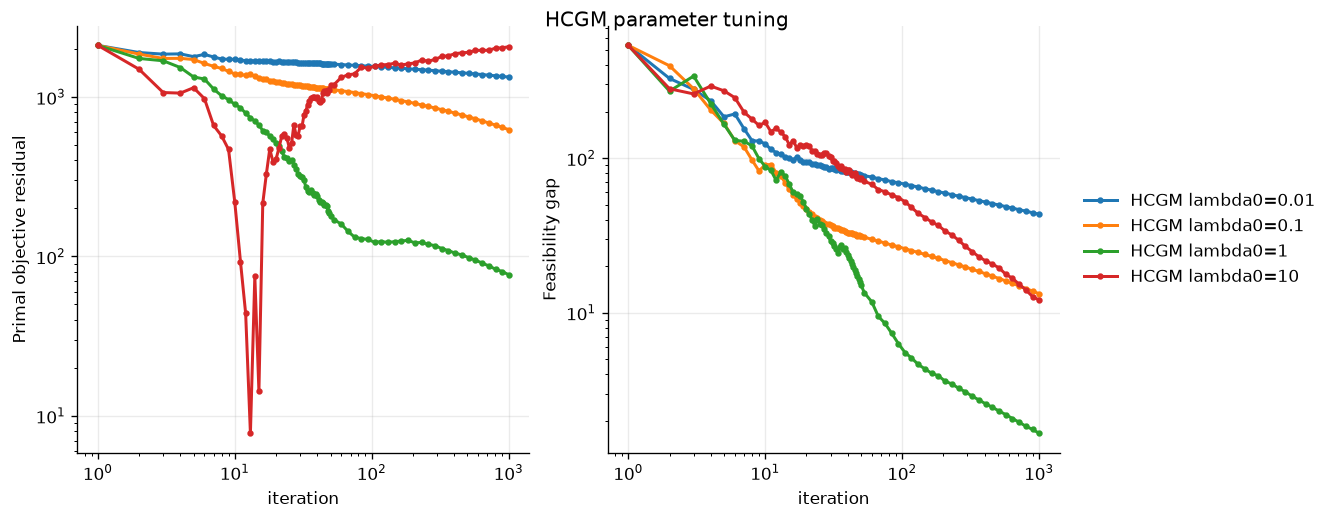

In [8]:
def objective_residual(history, fstar):
    primal = np.abs(np.asarray(history["primal_obj"], dtype=float) - fstar)
    return np.maximum(primal, 1e-16)


def plot_histories(histories, fstar, title=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)
    panels = [("primal", "Primal objective residual"), ("feasibility", "Feasibility gap")]
    for ax, (metric, ylabel) in zip(axes, panels):
        for name, history in histories.items():
            x = np.asarray(history["iter"], dtype=float)
            if metric == "primal":
                y = objective_residual(history, fstar)
            else:
                y = np.maximum(np.asarray(history["feasibility_gap"], dtype=float), 1e-16)
            ax.loglog(x, y, linewidth=1.8, marker="o", markersize=2.8, label=name)
        ax.set_xlabel("iteration")
        ax.set_ylabel(ylabel)
        ax.grid(True, which="major", alpha=0.25)
        ax.grid(False, which="minor")
    if title is not None:
        fig.suptitle(title, y=1.02)
    if histories:
        axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    return fig, axes


def _csv_slug(text):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", text).strip("_")


def export_history_csv(history, fstar, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    primal_residual = objective_residual(history, fstar)
    fields = ["iteration", "lmo_calls", "time", "primal_obj", "primal_residual", "feasibility_gap", "method", "parameter", "bound", "name"]
    with path.open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        for i in range(len(history["iter"])):
            writer.writerow({
                "iteration": history["iter"][i], "lmo_calls": history["lmo_calls"][i], "time": history["time"][i],
                "primal_obj": history["primal_obj"][i],
                "primal_residual": primal_residual[i],
                "feasibility_gap": history["feasibility_gap"][i], "method": history["method"],
                "parameter": history["parameter"], "bound": history["bound"] or "", "name": history["name"],
            })
    return path


def export_histories_csv(histories, fstar, prefix):
    output_dir = Path("results") / "maxcut"
    output_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    fields = ["iteration", "lmo_calls", "time", "primal_obj", "primal_residual", "feasibility_gap", "method", "parameter", "bound", "name"]
    for history in histories.values():
        run_path = output_dir / f"{prefix}_{_csv_slug(history['name'])}.csv"
        export_history_csv(history, fstar, run_path)
        with run_path.open(newline="") as stream:
            rows.extend(csv.DictReader(stream))
    combined_path = output_dir / f"{prefix}.csv"
    with combined_path.open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    return combined_path


tuning_histories = {}
if RUN_TUNING_EXPERIMENT:
    hcgm_tuning = {}
    for lambda0 in HCGM_LAMBDAS:
        history = hcgm_maxcut(lambda0, TUNING_MAXITER, eig_tol=EIG_TOL_TUNING)
        hcgm_tuning[history["name"]] = history
        print(f"finished {history['name']} | primal={history['primal_obj'][-1]:.6e} feas={history['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(hcgm_tuning)
    plot_histories(hcgm_tuning, f_star, "HCGM parameter tuning")
    plt.show()
    export_histories_csv(hcgm_tuning, f_star, "tuning_hcgm")
else:
    print("HCGM tuning disabled.")

## CGAL-cst tuning

CGAL-cst lambda0=0.01: iter=10 objective=-1.359339e+04 feasibility=7.768e+01
CGAL-cst lambda0=0.01: iter=20 objective=-1.337556e+04 feasibility=4.805e+01
CGAL-cst lambda0=0.01: iter=40 objective=-1.314410e+04 feasibility=3.355e+01
CGAL-cst lambda0=0.01: iter=80 objective=-1.290564e+04 feasibility=2.335e+01
CGAL-cst lambda0=0.01: iter=160 objective=-1.261640e+04 feasibility=1.497e+01
CGAL-cst lambda0=0.01: iter=320 objective=-1.228577e+04 feasibility=7.616e+00
CGAL-cst lambda0=0.01: iter=640 objective=-1.203382e+04 feasibility=2.236e+00
CGAL-cst lambda0=0.01: iter=1,000 objective=-1.204305e+04 feasibility=1.148e+00
finished CGAL-cst lambda0=0.01 | primal=-1.204305e+04 feas=1.148e+00
CGAL-cst lambda0=0.1: iter=10 objective=-1.312407e+04 feasibility=5.600e+01
CGAL-cst lambda0=0.1: iter=20 objective=-1.264525e+04 feasibility=1.976e+01
CGAL-cst lambda0=0.1: iter=40 objective=-1.218954e+04 feasibility=7.025e+00
CGAL-cst lambda0=0.1: iter=80 objective=-1.197987e+04 feasibility=3.167e+00
CGAL-

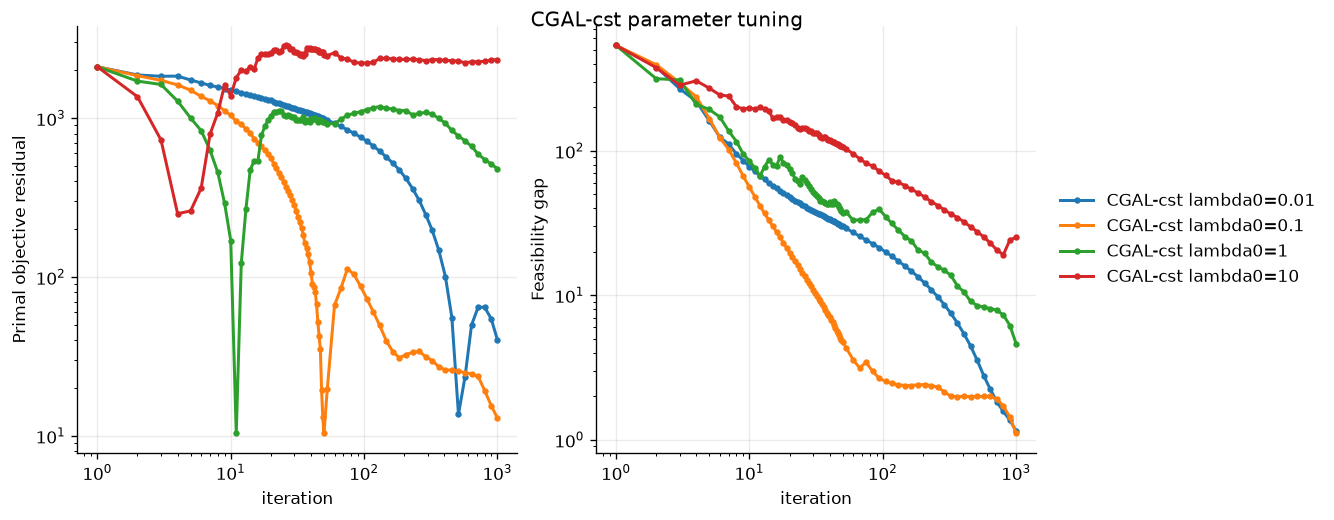

In [9]:
cgal_cst_tuning = {}
if RUN_TUNING_EXPERIMENT:
    for lambda0 in CGAL_LAMBDAS:
        history = cgal_maxcut(lambda0, "cst", TUNING_MAXITER, eig_tol=EIG_TOL_TUNING)
        cgal_cst_tuning[history["name"]] = history
        print(f"finished {history['name']} | primal={history['primal_obj'][-1]:.6e} feas={history['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(cgal_cst_tuning)
    plot_histories(cgal_cst_tuning, f_star, "CGAL-cst parameter tuning")
    plt.show()
    export_histories_csv(cgal_cst_tuning, f_star, "tuning_cgal_cst")
else:
    print("CGAL-cst tuning disabled.")

## CGAL-dcr tuning

CGAL-dcr lambda0=0.01: iter=10 objective=-1.366676e+04 feasibility=9.111e+01
CGAL-dcr lambda0=0.01: iter=20 objective=-1.358319e+04 feasibility=7.073e+01
CGAL-dcr lambda0=0.01: iter=40 objective=-1.351904e+04 feasibility=5.918e+01
CGAL-dcr lambda0=0.01: iter=80 objective=-1.345438e+04 feasibility=5.052e+01
CGAL-dcr lambda0=0.01: iter=160 objective=-1.338103e+04 feasibility=4.341e+01
CGAL-dcr lambda0=0.01: iter=320 objective=-1.329512e+04 feasibility=3.700e+01
CGAL-dcr lambda0=0.01: iter=640 objective=-1.320150e+04 feasibility=3.144e+01
CGAL-dcr lambda0=0.01: iter=1,000 objective=-1.313724e+04 feasibility=2.827e+01
finished CGAL-dcr lambda0=0.01 | primal=-1.313724e+04 feas=2.827e+01
CGAL-dcr lambda0=0.1: iter=10 objective=-1.336385e+04 feasibility=6.654e+01
CGAL-dcr lambda0=0.1: iter=20 objective=-1.312118e+04 feasibility=3.198e+01
CGAL-dcr lambda0=0.1: iter=40 objective=-1.294333e+04 feasibility=2.278e+01
CGAL-dcr lambda0=0.1: iter=80 objective=-1.279241e+04 feasibility=1.755e+01
CGAL-

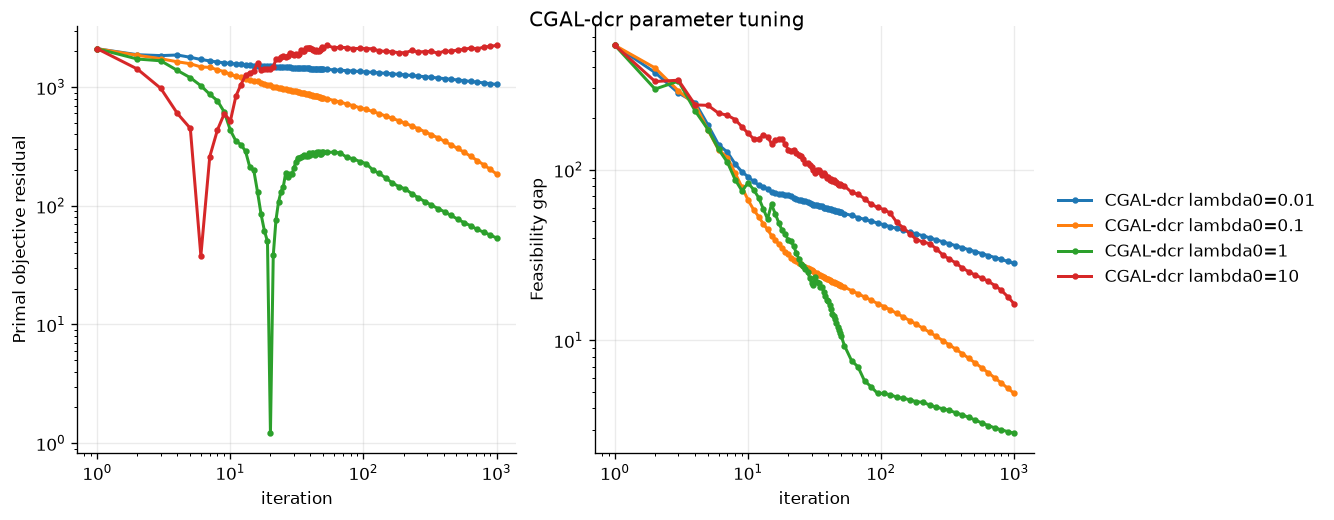

In [10]:
cgal_dcr_tuning = {}
if RUN_TUNING_EXPERIMENT:
    for lambda0 in CGAL_LAMBDAS:
        history = cgal_maxcut(lambda0, "dcr", TUNING_MAXITER, eig_tol=EIG_TOL_TUNING)
        cgal_dcr_tuning[history["name"]] = history
        print(f"finished {history['name']} | primal={history['primal_obj'][-1]:.6e} feas={history['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(cgal_dcr_tuning)
    plot_histories(cgal_dcr_tuning, f_star, "CGAL-dcr parameter tuning")
    plt.show()
    export_histories_csv(cgal_dcr_tuning, f_star, "tuning_cgal_dcr")
else:
    print("CGAL-dcr tuning disabled.")

## AdaPD tuning

AdaPD alpha=1: iter=10 objective=-1.395289e+04 feasibility=1.909e+02
AdaPD alpha=1: iter=20 objective=-1.386566e+04 feasibility=1.402e+02
AdaPD alpha=1: iter=40 objective=-1.378475e+04 feasibility=1.073e+02
AdaPD alpha=1: iter=80 objective=-1.370583e+04 feasibility=8.516e+01
AdaPD alpha=1: iter=160 objective=-1.361835e+04 feasibility=6.867e+01
AdaPD alpha=1: iter=320 objective=-1.351510e+04 feasibility=5.523e+01
AdaPD alpha=1: iter=640 objective=-1.339562e+04 feasibility=4.422e+01
AdaPD alpha=1: iter=1,000 objective=-1.330926e+04 feasibility=3.815e+01
finished AdaPD alpha=1 | primal=-1.330926e+04 feas=3.815e+01
AdaPD alpha=10: iter=10 objective=-1.373733e+04 feasibility=1.224e+02
AdaPD alpha=10: iter=20 objective=-1.356240e+04 feasibility=7.553e+01
AdaPD alpha=10: iter=40 objective=-1.338250e+04 feasibility=4.942e+01
AdaPD alpha=10: iter=80 objective=-1.319878e+04 feasibility=3.430e+01
AdaPD alpha=10: iter=160 objective=-1.298556e+04 feasibility=2.393e+01
AdaPD alpha=10: iter=320 objec

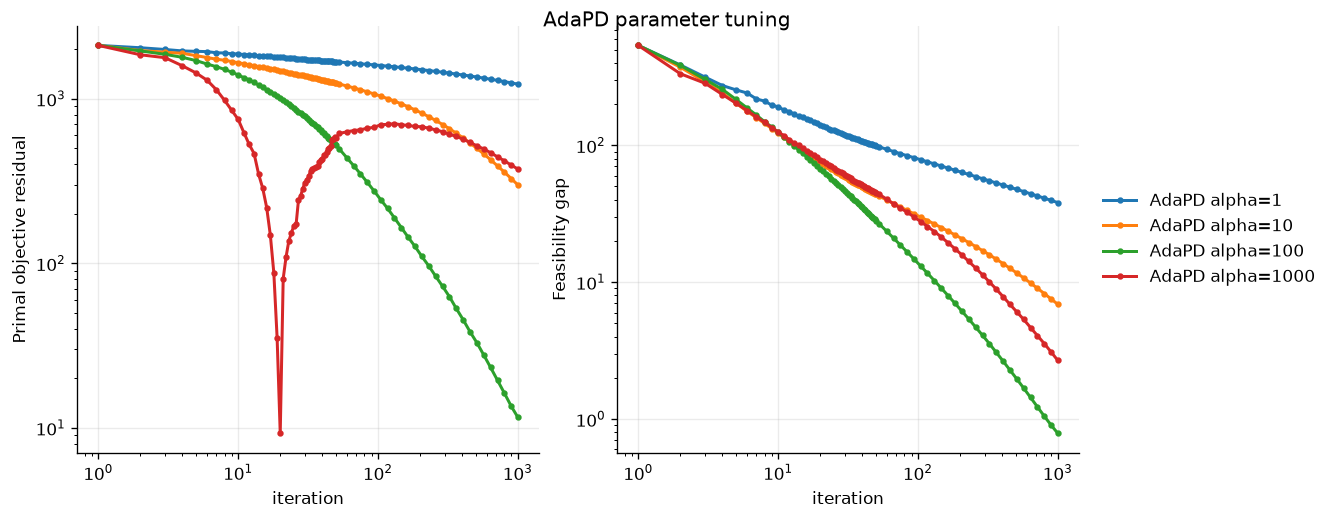

In [11]:
adapd_tuning = {}
if RUN_TUNING_EXPERIMENT:
    for alpha in ADAPD_ALPHAS:
        history = adapd_maxcut(alpha, TUNING_MAXITER, eig_tol=EIG_TOL_TUNING)
        adapd_tuning[history["name"]] = history
        print(f"finished {history['name']} | primal={history['primal_obj'][-1]:.6e} feas={history['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(adapd_tuning)
    plot_histories(adapd_tuning, f_star, "AdaPD parameter tuning")
    plt.show()
    export_histories_csv(adapd_tuning, f_star, "tuning_adapd")
else:
    print("AdaPD tuning disabled.")

## AccPD tuning

AccPD alpha=1: iter=10 objective=-1.384256e+04 feasibility=1.369e+02
AccPD alpha=1: iter=20 objective=-1.373717e+04 feasibility=9.610e+01
AccPD alpha=1: iter=40 objective=-1.363349e+04 feasibility=7.293e+01
AccPD alpha=1: iter=80 objective=-1.349892e+04 feasibility=5.503e+01
AccPD alpha=1: iter=160 objective=-1.333695e+04 feasibility=4.124e+01
AccPD alpha=1: iter=320 objective=-1.316633e+04 feasibility=3.126e+01
AccPD alpha=1: iter=640 objective=-1.295486e+04 feasibility=2.314e+01
AccPD alpha=1: iter=1,000 objective=-1.281380e+04 feasibility=1.876e+01
finished AccPD alpha=1 | primal=-1.281380e+04 feas=1.876e+01
AccPD alpha=10: iter=10 objective=-1.357559e+04 feasibility=7.439e+01
AccPD alpha=10: iter=20 objective=-1.329277e+04 feasibility=4.220e+01
AccPD alpha=10: iter=40 objective=-1.299628e+04 feasibility=2.584e+01
AccPD alpha=10: iter=80 objective=-1.263229e+04 feasibility=1.441e+01
AccPD alpha=10: iter=160 objective=-1.225948e+04 feasibility=5.896e+00
AccPD alpha=10: iter=320 objec

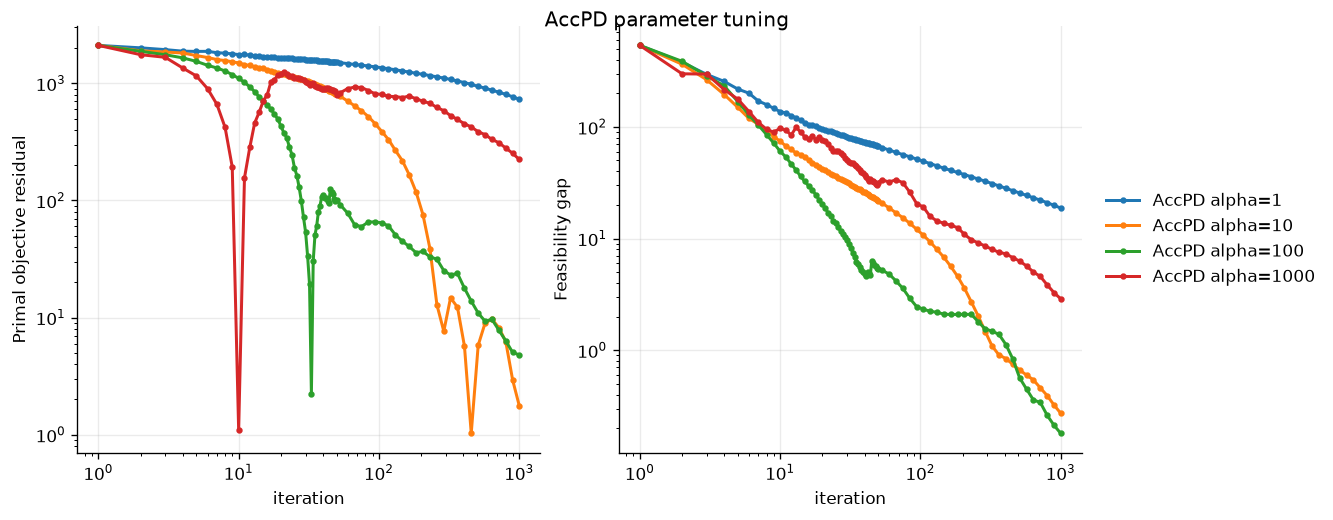

In [12]:
accpd_tuning = {}
if RUN_TUNING_EXPERIMENT:
    for alpha in ACCPD_ALPHAS:
        history = accpd_maxcut(alpha, TUNING_MAXITER, eig_tol=EIG_TOL_TUNING)
        accpd_tuning[history["name"]] = history
        print(f"finished {history['name']} | primal={history['primal_obj'][-1]:.6e} feas={history['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(accpd_tuning)
    plot_histories(accpd_tuning, f_star, "AccPD parameter tuning")
    plt.show()
    export_histories_csv(accpd_tuning, f_star, "tuning_accpd")
else:
    print("AccPD tuning disabled.")

## UniPD tuning

In [13]:
# unipd_tuning = {}
# if RUN_TUNING_EXPERIMENT:
#     for epsilon in UNIPD_EPSILONS:
#         history = unipd_maxcut(epsilon, TUNING_MAXITER)
#         unipd_tuning[history["name"]] = history
#         print(f"finished {history['name']} | primal={history['primal_obj'][-1]:.6e} feas={history['feasibility_gap'][-1]:.3e}")
#     tuning_histories.update(unipd_tuning)
#     plot_histories(unipd_tuning, f_star, "UniPD parameter tuning")
#     plt.show()
#     export_histories_csv(unipd_tuning, f_star, "tuning_unipd")
# else:
#     print("UniPD tuning disabled.")

## Optional long runs

HCGM lambda0=1: iter=10 objective=-1.298216e+04 feasibility=8.827e+01
HCGM lambda0=1: iter=20 objective=-1.262904e+04 feasibility=4.484e+01
HCGM lambda0=1: iter=40 objective=-1.231114e+04 feasibility=1.864e+01
HCGM lambda0=1: iter=80 objective=-1.221084e+04 feasibility=8.175e+00
HCGM lambda0=1: iter=160 objective=-1.220732e+04 feasibility=4.164e+00
HCGM lambda0=1: iter=320 objective=-1.219620e+04 feasibility=2.922e+00
HCGM lambda0=1: iter=640 objective=-1.217392e+04 feasibility=2.065e+00
HCGM lambda0=1: iter=1,280 objective=-1.215272e+04 feasibility=1.472e+00
HCGM lambda0=1: iter=2,560 objective=-1.213468e+04 feasibility=1.045e+00
HCGM lambda0=1: iter=5,120 objective=-1.212074e+04 feasibility=7.425e-01
HCGM lambda0=1: iter=10,000 objective=-1.211058e+04 feasibility=5.324e-01
finished HCGM lambda0=1 | primal=-1.211058e+04 feas=5.324e-01
CGAL-cst lambda0=0.1: iter=10 objective=-1.312407e+04 feasibility=5.600e+01
CGAL-cst lambda0=0.1: iter=20 objective=-1.264525e+04 feasibility=1.976e+01


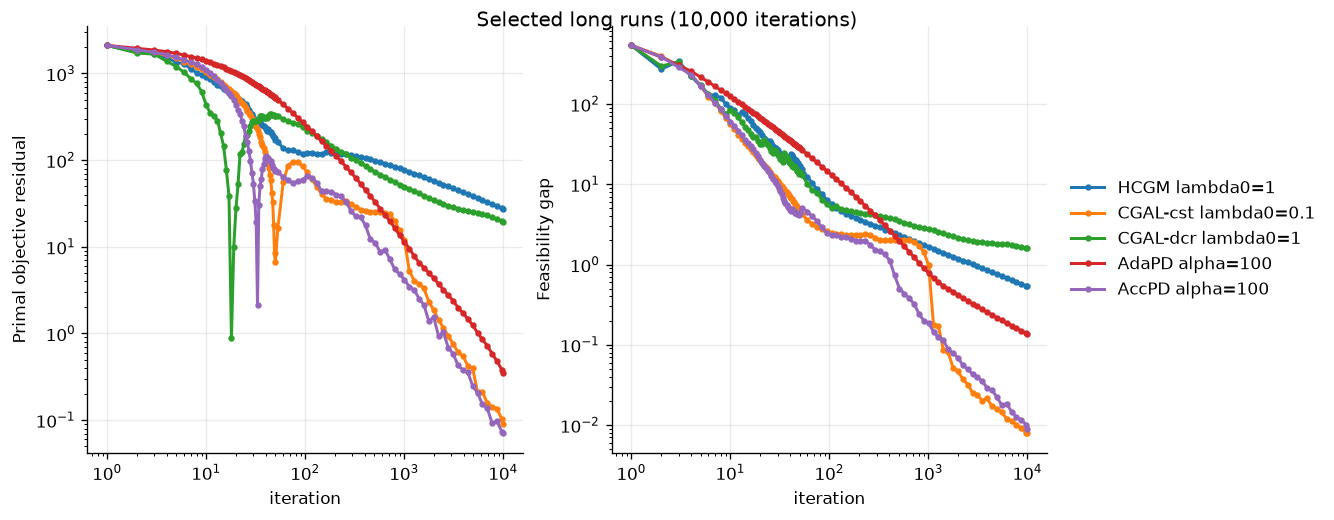

In [14]:
long_histories = {}

def run_selected(method, parameter, maxiter):
    if method == "HCGM":
        return hcgm_maxcut(parameter, maxiter)
    if method == "CGAL-cst":
        return cgal_maxcut(parameter, "cst", maxiter)
    if method == "CGAL-dcr":
        return cgal_maxcut(parameter, "dcr", maxiter)
    if method == "AdaPD":
        return adapd_maxcut(parameter, maxiter)
    if method == "AccPD":
        return accpd_maxcut(parameter, maxiter)
    if method == "UniPD":
        return unipd_maxcut(parameter, maxiter)
    raise ValueError(f"Unknown selected method: {method}")


if RUN_LONG_EXPERIMENT:
    for method, parameter in SELECTED_RUNS:
        history = run_selected(method, parameter, LONG_MAXITER)
        long_histories[history["name"]] = history
        print(f"finished {history['name']} | primal={history['primal_obj'][-1]:.6e} feas={history['feasibility_gap'][-1]:.3e}")
    export_histories_csv(long_histories, f_star, "long")
    plot_histories(long_histories, f_star, f"Selected long runs ({LONG_MAXITER:,} iterations)")
    plt.show()
else:
    print("Long runs disabled. Set RUN_LONG_EXPERIMENT = True after tuning.")

## Final comparison

In [15]:
comparison_histories = long_histories if long_histories else tuning_histories
if comparison_histories:
    print("method                                      primal residual   feasibility")
    for name, history in comparison_histories.items():
        primal_residual = objective_residual(history, f_star)
        print(f"{name:42s} {primal_residual[-1]:14.3e} {history['feasibility_gap'][-1]:12.3e}")
else:
    print("No experiment results are available.")

method                                      primal residual   feasibility
HCGM lambda0=1                                  2.738e+01    5.324e-01
CGAL-cst lambda0=0.1                            9.140e-02    7.900e-03
CGAL-dcr lambda0=1                              1.945e+01    1.607e+00
AdaPD alpha=100                                 3.508e-01    1.360e-01
AccPD alpha=100                                 7.056e-02    8.864e-03
